# Graphs in pyAgrum

| | | |
|-|-|-|
|[ ![Creative Commons License](images/cc4.png)](http://creativecommons.org/licenses/by-nc/4.0/) |[ ![aGrUM](images/logoAgrum.png)](https://pyagrum.gitlab.io) |[ ![interactive online version](images/atbinder.svg)](https://mybinder.org/v2/gl/agrumery%2FaGrUM/forBinder?urlpath=%2Fdoc%2Ftree%2Fwrappers%2Fpyagrum%2Fdoc%2Fsphinx%2Fnotebooks%2F03-Tutorial_graphs.ipynb)

pyAgrum provides several kinds of graphs: directed, undirected, mixed (arcs and edges), and graphs whose edges carry a mark at each end. The algorithms on these graphs are gathered in the module `pyagrum.graph`, one function per algorithm whatever the kind of graph.

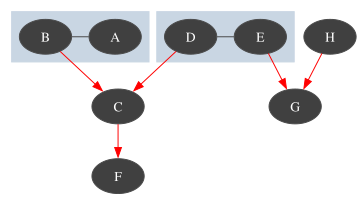

In [1]:
import pyagrum as gum
import pyagrum.graph as gg
import pyagrum.lib.notebook as gnb

gnb.show(gum.EssentialGraph(gum.fastBN("A->B->C<-D<-E->G<-H;C->F")))

## The kinds of graphs

The `fast*` functions build a graph from a string: `A->B` is an arc, `A-B` an edge, and in a marked graph, the marks are `-` (tail), `>`/`<` (arrowhead) and `o` (circle).

A name may be written between single quotes, as in every *fast* syntax: `'Visit Asia'->X` (a doubled quote stands for a quote). Without quotes, a node name contains neither space, `<` nor `>`.

In [2]:
dig = gum.fastDiGraph("A->B->C->A;C->D")  # a directed graph (cycles allowed)
dag = gum.fastDAG("A->B->C;D->C;C->E")  # a directed acyclic graph
ug = gum.fastUndiGraph("A-B-C-D-A;A-C")  # an undirected graph
mg = gum.fastMixedGraph("A->B-C-A")  # a mixed graph (arcs and edges)
pdag = gum.fastPDAG("A->B-C;C-D")  # a mixed graph without directed cycle
cg = gum.fastChainGraph("A->B-C<-D")  # a mixed graph without partially directed cycle
gnb.sideBySide(dig, dag, ug, mg, pdag, cg, captions=["DiGraph", "DAG", "UndiGraph", "MixedGraph", "PDAG", "ChainGraph"])

<!-- 0 --> 0 (0) A <!-- 1 --> 1 (1) B <!-- 0->1 --> 0->1 <!-- 2 --> 2 (2) C <!-- 1->2 --> 1->2 <!-- 2->0 --> 2->0 <!-- 3 --> 3 (3) D <!-- 2->3 --> 2->3 DiGraph,<!-- 0 --> 0 (0) A <!-- 1 --> 1 (1) B <!-- 0->1 --> 0->1 <!-- 2 --> 2 (2) C <!-- 1->2 --> 1->2 <!-- 4 --> 4 (4) E <!-- 2->4 --> 2->4 <!-- 3 --> 3 (3) D <!-- 3->2 --> 3->2 DAG,<!-- 0 --> 0 (0) A <!-- 1 --> 1 (1) B <!-- 0--1 --> 0--1 <!-- 2 --> 2 (2) C <!-- 0--2 --> 0--2 <!-- 3 --> 3 (3) D <!-- 0--3 --> 0--3 <!-- 1--2 --> 1--2 <!-- 2--3 --> 2--3 UndiGraph,<!-- 0 --> 0 (0) A <!-- 1 --> 1 (1) B <!-- 0->1 --> 0->1 <!-- 2 --> 2 (2) C <!-- 0->2 --> 0->2 <!-- 1->2 --> 1->2 MixedGraph,<!-- 0 --> 0 (0) A <!-- 1 --> 1 (1) B <!-- 0->1 --> 0->1 <!-- 2 --> 2 (2) C <!-- 1->2 --> 1->2 <!-- 3 --> 3 (3) D <!-- 2->3 --> 2->3 PDAG,cluster_0 <!-- 0 --> 0 (0) A <!-- 1 --> 1 (1) B <!-- 0->1 --> 0->1 <!-- 3 --> 3 (3) D <!-- 2 --> 2 (2) C <!-- 3->2 --> 3->2 <!-- 1->2 --> 1->2 ChainGraph


Some graphs are **immutable**: they represent a class of DAGs and are built by a factory. A `CPDAG` represents the Markov equivalence class of a DAG (its compelled arcs, the reversible ones as edges); an `MPDAG` adds background knowledge (more oriented arcs); an `EssentialGraph` is the CPDAG of a Bayesian network.

In [3]:
cpdag = gum.CPDAG.fromDAG(dag)
mpdag = gum.MPDAG.fromCPDAG(cpdag, {(0, 1)})  # knowing A->B
eg = gum.EssentialGraph(gum.fastBN("A->B->C;D->C;C->E"))
gnb.sideBySide(dag, cpdag, mpdag, eg, captions=["DAG", "its CPDAG", "an MPDAG (A->B known)", "EssentialGraph"])

<!-- 0 --> 0 (0) A <!-- 1 --> 1 (1) B <!-- 0->1 --> 0->1 <!-- 2 --> 2 (2) C <!-- 1->2 --> 1->2 <!-- 4 --> 4 (4) E <!-- 2->4 --> 2->4 <!-- 3 --> 3 (3) D <!-- 3->2 --> 3->2 DAG,cluster_0 <!-- 2 --> 2 (2) C <!-- 4 --> 4 (4) E <!-- 2->4 --> 2->4 <!-- 3 --> 3 (3) D <!-- 3->2 --> 3->2 <!-- 1 --> 1 (1) B <!-- 1->2 --> 1->2 <!-- 0 --> 0 (0) A <!-- 0->1 --> 0->1 its CPDAG,<!-- 0 --> 0 (0) A <!-- 1 --> 1 (1) B <!-- 0->1 --> 0->1 <!-- 2 --> 2 (2) C <!-- 1->2 --> 1->2 <!-- 4 --> 4 (4) E <!-- 2->4 --> 2->4 <!-- 3 --> 3 (3) D <!-- 3->2 --> 3->2 an MPDAG (A->B known),cluster_0 <!-- 2 --> 2 C <!-- 4 --> 4 E <!-- 2->4 --> 2->4 <!-- 3 --> 3 D <!-- 3->2 --> 3->2 <!-- 1 --> 1 B <!-- 1->2 --> 1->2 <!-- 0 --> 0 A <!-- 0->1 --> 0->1 EssentialGraph


The **marked graphs** have a mark at each end of their edges. A `PAG` (partial ancestral graph) represents a class of MAGs, a `MAG` (maximal ancestral graph) represents a DAG with latent variables.

In [4]:
marked = gum.fastMarkedGraph("A-B->C<->D;E o-> C")
pag = gum.fastPAG("A o-o B o-> C <-> D")
withLatent = gum.fastDAG("A->B->C;L->C;L->D")
mag = gum.MAG.fromDAG(withLatent, {withLatent.idFromName("L")})  # L is latent
gnb.sideBySide(marked, pag, mag, captions=["MarkedGraph", "PAG", "MAG (L latent)"])

<!-- 0 --> 0 (0) A <!-- 1 --> 1 (1) B <!-- 0->1 --> 0->1 <!-- 2 --> 2 (2) C <!-- 1->2 --> 1->2 <!-- 3 --> 3 (3) D <!-- 2->3 --> 2->3 <!-- 4 --> 4 (4) E <!-- 2->4 --> 2->4 MarkedGraph,<!-- 0 --> 0 (0) A <!-- 1 --> 1 (1) B <!-- 0->1 --> 0->1 <!-- 2 --> 2 (2) C <!-- 1->2 --> 1->2 <!-- 3 --> 3 (3) D <!-- 2->3 --> 2->3 PAG,<!-- 0 --> 0 (0) A <!-- 1 --> 1 (1) B <!-- 0->1 --> 0->1 <!-- 2 --> 2 (2) C <!-- 1->2 --> 1->2 <!-- 4 --> 4 (4) D <!-- 2->4 --> 2->4 MAG (L latent)


`gum.fastGraph` chooses the kind of graph from the description: an `UndiGraph` for edges only, a `DAG` (or a `DiGraph` if there is a directed cycle) for arcs only, a `PDAG` (or a `MixedGraph`) for arcs and edges, a `MarkedGraph` for marks. It relies on `gum.checkFastSyntax`, which gives every *fast* syntax for which a description is valid (graphs and graphical models).

In [5]:
for desc in ["A-B-C", "A->B->C->A", "A->B-C", "A o-> B", "'Visit Asia'->'X-ray'"]:
  print(
    f"{desc:24} {type(gum.fastGraph(desc)).__name__:12} {[s.name for s in gum.checkFastSyntax(desc).validSyntaxes()]}"
  )

A-B-C                    UndiGraph    ['UndiGraph', 'MixedGraph', 'MarkedGraph', 'MarkovRandomField']
A->B->C->A               DiGraph      ['DiGraph', 'MixedGraph', 'MarkedGraph', 'BayesNet', 'InfluenceDiagram']
A->B-C                   PDAG         ['MixedGraph', 'MarkedGraph']
A o-> B                  MarkedGraph  ['MarkedGraph', 'BayesNet', 'InfluenceDiagram']
'Visit Asia'->'X-ray'    DAG          ['DiGraph', 'MixedGraph', 'MarkedGraph', 'BayesNet', 'InfluenceDiagram']


## The algorithms: one function per algorithm

Each function of `pyagrum.graph` accepts a **family** of graphs, given by what the algorithm reads:

| family | reads | accepted graphs |
|-|-|-|
| A | the arcs | DiGraph, DAG, MixedGraph, PDAG, ChainGraph, CPDAG, MPDAG, EssentialGraph |
| E | the edges | UndiGraph, MixedGraph, PDAG, ChainGraph, CPDAG, MPDAG, EssentialGraph |
| AE | arcs and edges | MixedGraph, PDAG, ChainGraph, CPDAG, MPDAG, EssentialGraph |
| K | the marked edges | MarkedGraph, PAG, MAG |

An algorithm reads only what its family designates: on a PDAG, a function of the family A ignores the edges, a function of the family E ignores the arcs.

In [6]:
print("descendants of A (arcs only)  :", gg.descendants(pdag, "A"))
print("anteriors of D (arcs and edges):", gg.anteriors(pdag, "D"))
print("chordal (edges only)           :", gg.isChordal(pdag))

descendants of A (arcs only)  : {1}
anteriors of D (arcs and edges): {0, 1, 2}
chordal (edges only)           : True


A graph out of the family raises a `TypeError`:

In [7]:
try:
  gg.isChordal(mag)
except TypeError as e:
  print(e)

isChordal needs a graph with edges (UndiGraph, MixedGraph, PDAG, ChainGraph, CPDAG, MPDAG, EssentialGraph), got MAG


### Ancestors, descendants, anteriors

The nodes are given by their id or their name, one node or several. The search starts from the parents (children): a node of the set belongs to the result only if it is reached by a path of at least one step, on a cycle or from another node of the set.

In [8]:
print(gg.ancestors(dag, "C"))
print(gg.ancestors(dag, ["B", "C"]))  # B is an ancestor of C
print(gg.ancestors(dig, "A"))  # A is on a directed cycle
print(gg.anteriors(marked, "C"), gg.ancestors(marked, "C"))

{0, 1, 3}
{0, 1, 3}
{0, 1, 2}
{0, 1} {1}


### Cycles, orders and chordality

In [9]:
print(gg.hasDirectedCycle(dig), gg.topologicalOrder(dag))
print(gg.hasUndirectedCycle(ug), gg.isChordal(ug))
order = gg.lexBFS(ug)
print(order, gg.isPerfectEliminationOrdering(ug, list(reversed(order))))
print(gg.hasPartiallyDirectedCycle(mg), gg.hasPartiallyDirectedCycle(cg))

True [3, 0, 1, 2, 4]
True True
[0, 3, 2, 1] True
True False


### Orientation: from a DAG to its class and back

In [10]:
c = gg.cpdag(dag)  # same as gum.CPDAG.fromDAG(dag)
ext = gg.consistentExtension(c)  # a DAG of the class
closure = gg.meekClosure(gum.fastPDAG("A->B-C;C-D"))  # the Meek rules
oriented = gg.orientAsDAG(gum.fastPDAG("A->B-C;C-D"), {0: 2, 1: 2, 2: 2, 3: 2})
gnb.sideBySide(c, ext, closure, oriented, captions=["cpdag", "consistentExtension", "meekClosure", "orientAsDAG"])

cluster_0 <!-- 2 --> 2 (2) C <!-- 4 --> 4 (4) E <!-- 2->4 --> 2->4 <!-- 3 --> 3 (3) D <!-- 3->2 --> 3->2 <!-- 1 --> 1 (1) B <!-- 1->2 --> 1->2 <!-- 0 --> 0 (0) A <!-- 0->1 --> 0->1 cpdag,<!-- 0 --> 0 (0) A <!-- 1 --> 1 (1) B <!-- 0->1 --> 0->1 <!-- 2 --> 2 (2) C <!-- 1->2 --> 1->2 <!-- 4 --> 4 (4) E <!-- 2->4 --> 2->4 <!-- 3 --> 3 (3) D <!-- 3->2 --> 3->2 consistentExtension,<!-- 0 --> 0 (0) A <!-- 1 --> 1 (1) B <!-- 0->1 --> 0->1 <!-- 2 --> 2 (2) C <!-- 1->2 --> 1->2 <!-- 3 --> 3 (3) D <!-- 2->3 --> 2->3 meekClosure,<!-- 0 --> 0 (0) A <!-- 1 --> 1 (1) B <!-- 0->1 --> 0->1 <!-- 2 --> 2 (2) C <!-- 1->2 --> 1->2 <!-- 3 --> 3 (3) D <!-- 2->3 --> 2->3 orientAsDAG


### Separation

`separation` uses the criterion of the class of the graph: d-separation for DAG, CPDAG, MPDAG and EssentialGraph, c-separation for PDAG and ChainGraph, m-separation for MAG. The three criteria are equal on a DAG.

In [11]:
for g in (dag, cpdag, gum.MAG.fromDAG(dag)):
  print(f"{type(g).__name__:6}", gg.separation(g, "A", "D"), gg.separation(g, "A", "D", "C"))

# c-separation: the parents of the chain component {B, C} are married
print("ChainGraph", gg.separation(cg, "A", "D"), gg.separation(cg, "A", "D", "B"))

DAG    True False
CPDAG  True False
MAG    True False
ChainGraph True False
